# CellPLM Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 03.12.2024
- Date of Last Modification: 04.12.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

- Install the cellplm conda environment ```../../envs/cellplm.yaml```, then run ```pip install -r requirements.txt``` inside the ```./CellPLM``` repository.
- Download the model checkpoint as described here https://github.com/OmicsML/CellPLM/tree/main and put it into the folder ```./CellPLM/ckpt```.
- This notebook follows the tutorial from https://github.com/OmicsML/CellPLM/blob/main/tutorials/cell_embedding.ipynb.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import os

import anndata as ad
import pandas as pd
import scanpy as sc
from CellPLM.pipeline.cell_embedding import CellEmbeddingPipeline
from CellPLM.utils import set_seed
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 Configure Paths

In [20]:
st_data_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
cellplm_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/analysis/benchmarking/CellPLM'

### 1.3 Define Config

In [30]:
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11', 'batch19', 'batch32']
batch_key = 'sample'
niche_key = 'niche_type'
latent_cluster_key = 'predicted_niche'
latent_leiden_resolution = 0.4

In [7]:
PRETRAIN_VERSION = '20231027_85M'
DEVICE = 'cuda:0'

### 1.4 Run Notebook Setup

In [17]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

In [18]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/metrics', exist_ok=True)

In [10]:
set_seed(42)

## 2. Data

In [11]:
# Load hold out skin samples and concatenate in one adata object
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


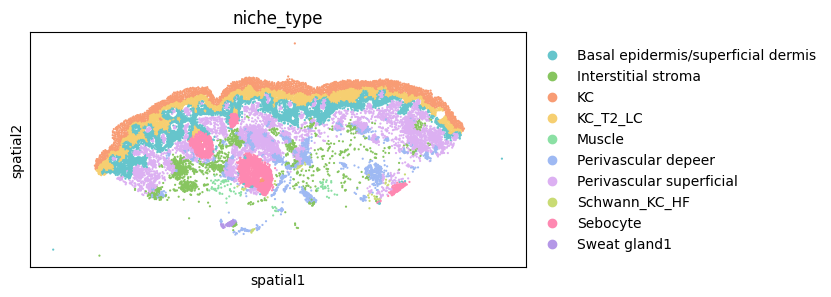

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


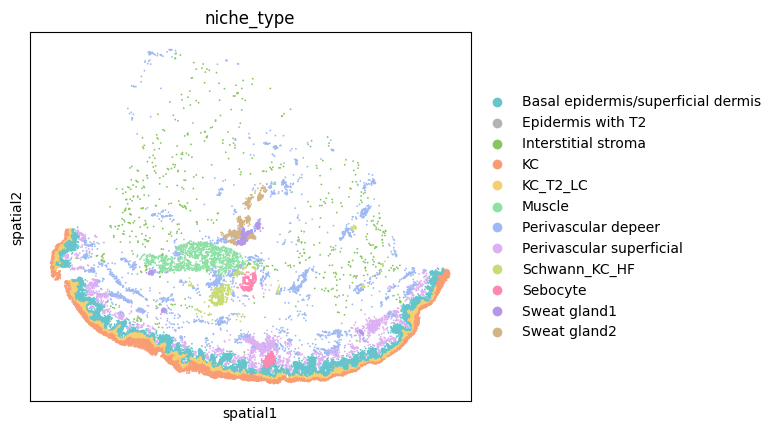

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


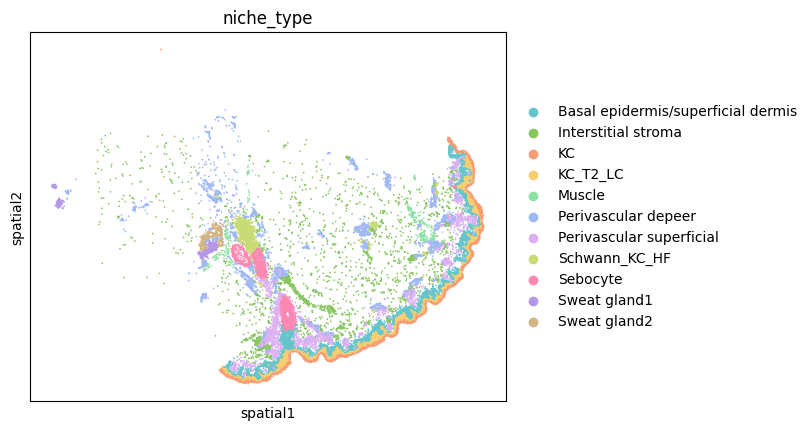

In [14]:
# Plot ground truth niches
spot_sizes = [20, 20, 20]
custom_palette_ground_truth = {niche: custom_palette[number] for niche, number in zip(
    adata.obs[niche_key].unique().tolist(), custom_palette)}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_ground_truth_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=custom_palette_ground_truth,
                  spot_size=spot_sizes[i],
                  save=file_name)

## 3. Model

### 3.1 Zero-shot Niche Identification

In [21]:
# Init cell embedding pipeline
pipeline = CellEmbeddingPipeline(pretrain_prefix=PRETRAIN_VERSION, # Specify the pretrain checkpoint to load
                                 pretrain_directory=f'{cellplm_folder_path}/ckpt')
pipeline.model

OmicsFormer(
  (embedder): OmicsEmbeddingLayer(
    (act): ReLU()
    (norm0): GroupNorm(4, 1024, eps=1e-05, affine=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (extra_linear): Sequential(
      (0): Linear(in_features=1024, out_features=1024, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.2, inplace=False)
      (3): GroupNorm(4, 1024, eps=1e-05, affine=True)
    )
    (pe_enc): Sinusoidal2dPE(
      (pe_enc): Embedding(10000, 1024)
    )
    (feat_enc): OmicsEmbedder()
  )
  (mask_model): MaskBuilder()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): FlowformerLayer(
        (self_attn): Flow_Attention(
          (query_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (key_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (value_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (out_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (drop

In [22]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Automatically converting gene symbols to ensembl ids...


INFO:biothings.client:querying 1-1000...
INFO:biothings.client:done.
INFO:biothings.client:querying 1001-2000...
INFO:biothings.client:done.
INFO:biothings.client:querying 2001-3000...
INFO:biothings.client:done.
INFO:biothings.client:querying 3001-4000...
INFO:biothings.client:done.
INFO:biothings.client:querying 4001-4948...
INFO:biothings.client:done.
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.
/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/CellPLM/utils/data.py:81: UserWarning: Batch labels not found in AnnData.obs. All cells are considered from the same sample by default.
  warnings.warn(


After filtering, 4633 genes remain.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/CellPLM/utils/data.py:20: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at ../aten/src/ATen/SparseCsrTensorImpl.cpp:54.)
  return torch.sparse_csr_tensor(x.indptr, x.indices, x.data, (x.shape[0], x.shape[1])).to_sparse().float().coalesce()


In [31]:
# Compute neighbors, UMAP and Leiden clustering (matching the number of clusters with the ground truth - 12)
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                method='rapids',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb',
           method='rapids')
sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/neighbors/__init__.py:704: FutureWarning: `transformer='rapids'` is deprecated. Use `rapids_singlecell.tl.neighbors` instead.
  warn(msg, FutureWarning)


/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/tools/_umap.py:233: FutureWarning: `method='rapids'` is deprecated. Use `rapids_singlecell.tl.louvain` instead.
  warnings.warn(msg, FutureWarning)


/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


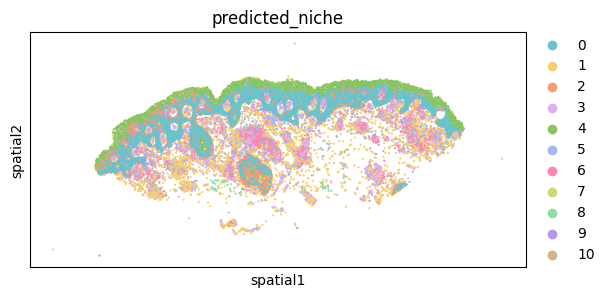

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


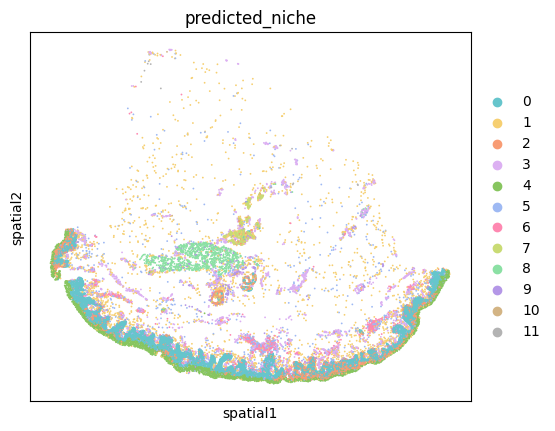

/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


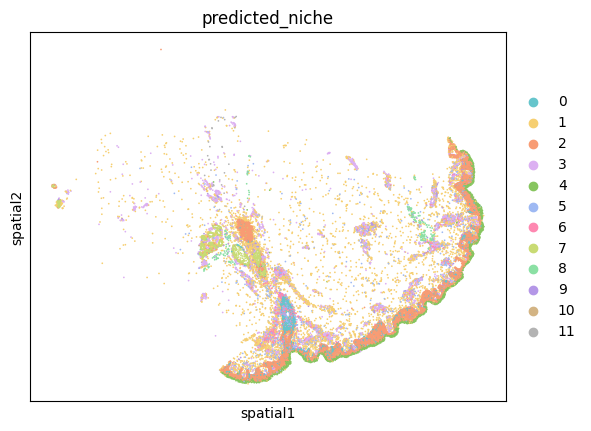

In [32]:
# Plot predicted niches
spot_sizes = [20, 20, 20]

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_cellplm_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [28]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]

nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)

print(f'NMI is {nmi}. ARI is {ari}.')

NMI is 0.41135540687499744. ARI is 0.257706381195822.


In [29]:
metrics_df = pd.DataFrame({'Metric': ['NMI', 'ARI'], 'Value': [nmi, ari]})
metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/metrics/cellplm.csv', index=False)